# Lab RAG — Designing Machine Learning Systems (v2)
Experimento da família F4 (controle do processo) sobre o livro *Designing Machine Learning Systems* (Chip Huyen, 2022), PDF integral.

**v2** — correções da avaliação v1 (2026-10-15, congelada em `results/run_2026-10-15_v1/`):
- 7 variantes: `pure_llm` · `baseline` · `adaptive_route` · `adaptive_expansion` · `adaptive_full` · `self_rag` · `embedding`;
- Adaptive RAG com **roteador LLM de 3 níveis** (LABEL_A/B/C — Jeong et al. 2024) e subqueries derivadas da pergunta (sem queries genéricas fixas);
- Self-RAG: verificador + retry **com nova recuperação** (subquery do draft, RRF);
- **seeds 42/43/44 por repetição** (variância amostral real, não cópias);
- gabarito por **rubrica** definido antes da run (`answer_rubric`);
- grader com **dedup + 2 votos** por resposta única (auto-concordância ≥ 90%);
- persistência por (variante, repetição) com **resume** e trace em APPEND;
- detecção unificada de abstenção (`prompts/abstention.txt`).


## 0. Ambiente de Execução

## 0a. Setup Colab (Fase 3 — executar primeiro)

Célula única e **idempotente** para rodar este notebook no Colab:
1. monta o Google Drive;
2. valida o PDF do livro contra o sha256 congelado da run v1 (`688ba89d…`); 
3. clona a branch `feat/v2-experiment` em `/content/rag-dmls-lab` (reuso se já existir); 
4. copia o PDF para `corpus/documentos/`; 
5. aponta `results_dir` para o Drive (`rag-dmls-v2/results/`) e cria os
   diretórios; 
6. entra na raiz do clone — as células seguintes passam a rodar de lá.

**Abrir este notebook no Colab:** https://colab.research.google.com/github/micarlio/rag-dmls-lab/blob/feat/v2-experiment/notebook.ipynb

**Desconexões:** rode as células de novo de cima para baixo — o setup
reaproveita tudo (Drive, clone, PDF) e a run oficial retoma por
(variante, repetição) pela célula do experimento. Evite `git pull` no
meio da run (código mudando entre repetições quebra comparabilidade).


In [ ]:
import os, shutil, hashlib, json, subprocess
from pathlib import Path

REPO_URL = 'https://github.com/micarlio/rag-dmls-lab.git'
BRANCH = 'feat/v2-experiment'
DRIVE_BASE = Path('/content/drive/MyDrive/rag-dmls-v2')
PDF_DRIVE = DRIVE_BASE / 'designing-machine-learning-systems-2022.pdf'
PDF_SHA = '688ba89df4e8fbcf681218e194017ad665ed2a1641916224758b9a6c17e29fab'
CLONE = Path('/content/rag-dmls-lab')

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, 'rb') as fh:
        for block in iter(lambda: fh.read(1 << 20), b''):
            h.update(block)
    return h.hexdigest()

def setup_colab():
    # 1) montar o Drive
    try:
        from google.colab import drive
    except ImportError:
        print('fora do Colab — execução local; setup pulado.')
        return
    if not Path('/content/drive/MyDrive').exists():
        drive.mount('/content/drive')
        print('Drive montado.')

    # 2) localizar e validar o PDF
    if PDF_DRIVE.exists():
        pdf_src = PDF_DRIVE
    else:
        import glob as _glob
        cand = _glob.glob('/content/drive/MyDrive/**/*designing*machine*.pdf',
                          recursive=True)
        assert cand, (
            f'PDF não encontrado: coloque o livro em {DRIVE_BASE}/ '
            'ou informe o caminho em PDF_DRIVE.')
        pdf_src = Path(cand[0])
        print(f'PDF encontrado em fallback: {pdf_src}')
    pdf_sha = sha256_file(pdf_src)
    if pdf_sha != PDF_SHA:
        raise AssertionError(
            f'sha256 do PDF **diverge** do corpus da run v1!\n'
            f'  encontrado : {pdf_sha}\n  esperado   : {PDF_SHA}\n'
            'NÃO rode o experimento sobre outro PDF (proveniência).')
    print(f'PDF OK: {pdf_src.name} ({pdf_sha[:12]}..., sha256 da v1 ✓)')

    # 3) clone (reusa se já existir)
    if CLONE.exists():
        r = subprocess.run(['git', '-C', str(CLONE), 'status', '-sb'],
                           capture_output=True, text=True)
        if r.returncode == 0 and BRANCH in r.stdout:
            print(f'clone existente em {CLONE} ({r.stdout.strip()[:60]}) — reuso.')
        else:
            raise AssertionError(
                f'{CLONE} existe mas não é o clone da {BRANCH} — remova manualmente.')
    else:
        subprocess.run(['git', 'clone', '--branch', BRANCH, '--depth', '10',
                        REPO_URL, str(CLONE)], check=True)
        print(f'clone criado: {CLONE}')

    # 4) PDF dentro do clone
    dst = CLONE / 'corpus' / 'documentos' / pdf_src.name
    if not dst.exists() or sha256_file(dst) != PDF_SHA:
        dst.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(pdf_src, dst)
        assert sha256_file(dst) == PDF_SHA
        print(f'PDF copiado para {dst}')
    else:
        print(f'PDF já presente em {dst} (hash ✓)')

    # 5) results_dir -> Drive
    cfg_path = CLONE / 'configs' / 'experiment.json'
    cfg = json.loads(cfg_path.read_text(encoding='utf-8'))
    if cfg.get('results_dir') != 'drive':
        cfg['results_dir'] = 'drive'
        cfg_path.write_text(json.dumps(cfg, ensure_ascii=False, indent=2),
                            encoding='utf-8')
        print('config patch: results_dir -> drive')
    results_dir = DRIVE_BASE / 'results'
    (results_dir / 'traces').mkdir(parents=True, exist_ok=True)
    print(f'results: {results_dir}')

    # 6) entrar na raiz do clone
    os.chdir(CLONE)
    h = subprocess.run(['git', '-C', str(CLONE), 'log', '-1', '--oneline'],
                       capture_output=True, text=True).stdout.strip()
    print(f'HEAD: {h}')
    print(f'cwd: {Path.cwd()}')
    print('\nPRÓXIMO: rodar as células seguintes de cima para baixo '
          '(dependências -> Ollama -> config -> smoke -> run).')

setup_colab()


In [ ]:
# Verificação da GPU usada na execução
import subprocess

def _query_gpu():
    return subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total',
                           '--format=csv,noheader'],
                          capture_output=True, text=True, check=False)

try:
    gpu = _query_gpu()
    if gpu.returncode == 0 and gpu.stdout.strip():
        print(f"GPU: {gpu.stdout.strip()}")
    else:
        print("Nenhuma GPU detectada — execução em CPU.")
except FileNotFoundError:
    print("nvidia-smi indisponível — execução em CPU; "
          "latências não comparáveis com a run oficial (Colab GPU).")


GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition, 97887 MiB


# 1. Dependências do projeto

In [ ]:
!pip install -q pypdf pandas numpy scikit-learn requests matplotlib seaborn openpyxl


### Instalação e configuração do Ollama

O Ollama não vem pré-instalado no Colab. São três passos:

1. Instalar o executável (célula 2)
2. Iniciar o servidor em segundo plano — `ollama serve` (célula 3)
3. Baixar os modelos: gerador do experimento (`qwen2.5:7b`) e de embeddings (`nomic-embed-text`) (célula 4)

In [414]:
%%bash
# 1. Instalacao do Ollama (runtime dos modelos locais) - CELULA 2
# zstd: dependencia do instalador oficial. pciutils (lspci): sem ele o
# instalador nao detecta a GPU e baixa o runtime SEM CUDA (geracao em CPU).
set -e
sudo apt-get update -qq && sudo apt-get install -y -qq zstd pciutils
curl -fsSL https://ollama.com/install.sh | sh
ollama --version
nvidia-smi -L || true


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
>>> Cleaning up old version at /usr/local/lib/ollama
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.


In [415]:
# 2. Iniciar o servidor Ollama (o instalador não sobe o serviço no Colab) - CELULA 3
import subprocess, time, os, requests

subprocess.run(["pkill", "ollama"])  # idempotente: encerra instâncias de execuções anteriores
time.sleep(2)

# host explícito evita falha de resolução de interface no Colab
env = {**os.environ, "OLLAMA_HOST": "127.0.0.1:11434"}
subprocess.Popen(["ollama", "serve"], env=env,
                 stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)

for _ in range(25):
    try:
        if requests.get("http://127.0.0.1:11434/").status_code == 200:
            print("✅ Servidor Ollama ativo em http://127.0.0.1:11434")
            break
    except requests.exceptions.ConnectionError:
        pass
    time.sleep(1)
else:
    raise RuntimeError("Ollama não subiu em 25s — verifique a célula de instalação.")

✅ Servidor Ollama ativo em http://127.0.0.1:11434


In [416]:
# 4. Download dos modelos: gerador do experimento +  - CELULA 4
if 'config' not in globals():
    raise RuntimeError("config não carregada — execute antes a célula do configs/experiment.json.")
model_name = config['generator_model']

!ollama pull {model_name}
!ollama pull nomic-embed-text   # embeddings da correção F2 (retrieval denso)

print(f"✅ '{model_name}' e 'nomic-embed-text' prontos para uso!")




✅ 'qwen2.5:7b' e 'nomic-embed-text' prontos para uso!


In [ ]:
!curl http://127.0.0.1:11434/api/generate -d '{"model":"qwen2.5:7b","prompt":"ok","stream":false}'
!curl http://127.0.0.1:11434/api/ps

{"model":"qwen2.5:7b","created_at":"2026-10-15T00:23:03.608296257Z","response":"当然，需要帮助时随时告诉我！你有什么问题或需要什么帮助吗？","done":true,"done_reason":"stop","context":[151644,8948,198,2610,525,1207,16948,11,3465,553,54364,14817,13,1446,525,264,10950,17847,13,151645,198,151644,872,198,562,151645,198,151644,77091,198,103942,3837,85106,100364,13343,102422,106525,6313,56568,104139,86119,57191,85106,99245,100364,101037,11319],"total_duration":1837613887,"load_duration":1718607999,"prompt_eval_count":30,"prompt_eval_cached_count":0,"prompt_eval_duration":41402000,"eval_count":18,"eval_duration":76020000}{"models":[{"name":"qwen2.5:7b","model":"qwen2.5:7b","size":6608251780,"digest":"845dbda0ea48ed749caafd9e6037047aa19acfcfd82e704d7ca97d631a0b697e","details":{"parent_model":"","format":"gguf","family":"qwen2","families":["qwen2"],"parameter_size":"7.6B","quantization_level":"Q4_K_M"},"expires_at":"2026-10-15T00:28:03.608832907Z","size_vram":6608251780,"context_length":32768,"runner":"llamacpp"}]}

## Configuração do experimento

Localiza a raiz do projeto (`find_root()` — funciona no Colab e em execução local,
buscando a pasta que contém `questions.json` + `experiment.json`) e carrega:

- `experiment.json` — modelos, top_k, parâmetros de chunking
- `questions.json` — 20 questões com categoria e dificuldade

Localiza o PDF do livro
(`find_pdf_path()` — busca em `corpus/documentos/`, raiz do projeto e `/content`).

Valida a estrutura dos arquivos antes de qualquer execução — erros de
configuração aparecem aqui, não no meio do experimento.

In [ ]:
# Configuração do projeto: imports, config e localização do corpus/da v2
import json, time, hashlib, re
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import requests
from pypdf import PdfReader
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

def find_root():
    """Localiza a raiz do projeto (Colab ou execução local)."""
    def has_markers(c):
        if not (c / 'questions.json').exists():
            return False
        return ((c / 'experiment.json').exists()
                or (c / 'configs' / 'experiment.json').exists())
    bases = [Path.cwd(), Path('/content')]
    candidates = list(bases)
    for base in bases:
        if base.exists():
            candidates.extend(p.parent for p in base.glob('*/questions.json'))
            candidates.extend(p.parent for p in base.glob('*/*/questions.json'))
    candidates.extend(Path.cwd().parents)
    for c in candidates:
        if has_markers(c):
            return c
    return Path.cwd()

ROOT = find_root()

def load_json(path):
    if not path.exists():
        raise FileNotFoundError(f'Arquivo não encontrado: {path}')
    with open(path, 'r', encoding='utf-8') as fh:
        return json.load(fh)

if (ROOT / 'experiment.json').exists():
    CONFIG_PATH = ROOT / 'experiment.json'
elif (ROOT / 'configs' / 'experiment.json').exists():
    CONFIG_PATH = ROOT / 'configs' / 'experiment.json'
else:
    CONFIG_PATH = ROOT / 'experiment.json'

QUESTIONS_PATH = ROOT / 'questions.json'
config = load_json(CONFIG_PATH)
questions = load_json(QUESTIONS_PATH)

assert questions.get('questions'), "questions.json não contém a lista 'questions'."
required_q = {'id', 'question', 'category', 'difficulty', 'answer_key', 'answer_rubric'}
missing = [k for k in required_q if k not in questions['questions'][0]]
assert not missing, f"Campos ausentes nas perguntas: {missing}"

VARIANTS = list(config['variants'].keys())            # roster v2
SEEDS = list(config['seeds_per_repetition'])          # seeds por repetição
N_REPS = {v: int(r) for v, r in config['variants'].items()}
assert all(r == len(SEEDS) for r in N_REPS.values()), 'repetições != seeds por repetição'

# RESULTS_DIR: 'drive' persiste no Google Drive (Colab); padrão = results/v2 local
if config.get('results_dir') == 'drive':
    _drive = Path('/content/drive/MyDrive')
    if not _drive.exists():
        raise FileNotFoundError(
            'results_dir=drive exige o Google Drive montado antes desta célula '
            '(from google.colab import drive; drive.mount("/content/drive"))')
    RESULTS_DIR = _drive / 'rag-dmls-v2' / 'results'
else:
    RESULTS_DIR = ROOT / 'results' / 'v2'
TRACES_DIR = RESULTS_DIR / 'traces'

def sha256_file(path):
    d = hashlib.sha256()
    with open(path, 'rb') as fh:
        for block in iter(lambda: fh.read(1 << 20), b''):
            d.update(block)
    return d.hexdigest()

def find_pdf_path(root=None):
    root = Path(root or ROOT)
    for folder in [root / 'corpus' / 'documentos', root, Path('/content')]:
        if not folder.exists():
            continue
        matches = sorted(p for p in folder.rglob('*.pdf')
                         if not p.name.startswith(('.', '~', '$')))
        if matches:
            return matches[0]
    raise FileNotFoundError('PDF do livro não encontrado em corpus/documentos/.')

pdf_path = find_pdf_path(ROOT)
corpus_sha = sha256_file(pdf_path)
_manifest_run = load_json(RESULTS_DIR.parent / 'run_2026-10-15_v1' / 'run_manifest.json') \
    if (RESULTS_DIR.parent / 'run_2026-10-15_v1' / 'run_manifest.json').exists() else {}
if _manifest_run:
    _run_pdf = _manifest_run['corpus_sha256']
    if corpus_sha != _run_pdf:
        print(f'AVISO: sha256 do PDF local ({corpus_sha[:8]}) difere do PDF da run v1 '
              f'({_run_pdf[:8]}). A comparação de resultados v1×v2 não será '
              f'proveniente do mesmo corpus.')

print(f'Projeto: {config.get("project_name")} | v2 | raiz: {ROOT}')
print(f'Version: {VARIANTS} | seeds: {SEEDS}')
print(f'RESULTS_DIR: {RESULTS_DIR} | PDF: {pdf_path.name} ({corpus_sha[:8]})')


## Corpus: leitura e chunking\n\n`read_pdf_pages()` extrai o texto de todas as páginas do PDF e
`chunk_pages_with_source()` divide em blocos de tamanho fixo com sobreposição,
retornando a página de origem de cada chunk. Os parâmetros vêm do config
(`chunk_size_chars`, `chunk_overlap_chars`) — fonte única. Os chunks alimentam
os retrievers das variantes do experimento.\n

In [419]:
def read_pdf_pages(pdf_path):
    """Retorna lista de (numero_real_da_pagina, texto) apenas páginas com texto."""
    reader = PdfReader(pdf_path)
    pages = []
    for page_num, page in enumerate(reader.pages, start=1):
        text = re.sub(r'\s+', ' ', page.extract_text() or '').strip()
        if text:
            pages.append((page_num, text))
    return pages


def _validate_chunk_params(chunk_size, overlap):
    if not (0 < overlap < chunk_size):
        raise ValueError(
            f'chunk_size ({chunk_size}) deve exceder overlap ({overlap}).')


def chunk_pages_with_source(pages, chunk_size=800, overlap=120):
    """pages: lista de (numero_real, texto). Retorna (chunks, chunk_pages)."""
    _validate_chunk_params(chunk_size, overlap)
    full_text, page_starts = '', []
    for page_num, page_text in pages:
        page_starts.append((len(full_text), page_num))
        full_text += page_text + ' '

    chunks, chunk_pages = [], []
    step = chunk_size - overlap
    for start in range(0, len(full_text), step):
        piece = full_text[start:start + chunk_size].strip()
        if piece:
            page = max(num for pos, num in page_starts if pos <= start)
            chunks.append(piece)
            chunk_pages.append(page)
        if start + chunk_size >= len(full_text):
            break
    return chunks, chunk_pages

# 7. Chunking do corpus com página de origem (usa os parâmetros do config)
pages = read_pdf_pages(pdf_path)  # lista de (numero_real_da_pagina, texto)

# remove paginas de boilerplate do PDF (avisos de draft do editor)
BOILER_PATTERN = re.compile(
    r'(github repo will be made active'
    r'|note: this book is in draft'
    r'|will be updated before publication'
    r'|comments about how we might improve the content)',
    re.IGNORECASE)
_pages0 = len(pages)
pages = [(n, t) for n, t in pages if not BOILER_PATTERN.search(t)]
if _pages0 != len(pages):
    print(f'Boilerplate: {_pages0 - len(pages)} paginas removidas.')

chunk_size = config['chunk_size_chars']
overlap = config['chunk_overlap_chars']
chunks, chunk_pages = chunk_pages_with_source(pages, chunk_size=chunk_size, overlap=overlap)

print(f'Páginas com texto: {len(pages)}')
print(f'Chunks gerados: {len(chunks)} (chunk_size={chunk_size}, overlap={overlap})')
print(f'Página do primeiro chunk: {chunk_pages[0]}')


Páginas com texto: 313
Chunks gerados: 713 (chunk_size=800, overlap=120)
Página do primeiro chunk: 2


In [420]:
# 8. Índice de retrieval do baseline: TF-IDF - CELULA 8
def build_index(chunks):
    """Constrói o índice TF-IDF do baseline (unigramas e bigramas)."""
    vectorizer = TfidfVectorizer(stop_words='english', ngram_range=(1, 2))
    matrix = vectorizer.fit_transform(chunks)
    return vectorizer, matrix

vectorizer, matrix = build_index(chunks)
print(f"Índice TF-IDF: {matrix.shape[0]} chunks × {matrix.shape[1]} termos de vocabulário")

Índice TF-IDF: 713 chunks × 37800 termos de vocabulário


In [ ]:
# 9. Índice de embeddings (nomic-embed-text) - o retrieval hibrido usa em TODAS as variantes com retrieval; sem Ollama, cai para lexical puro.
EMBED_MODEL = config['embedding_model']
retrieve_top_k_embedding = None

def ollama_embed(texts, batch=32):
    vecs = []
    for i in range(0, len(texts), batch):
        r = requests.post(
            'http://127.0.0.1:11434/api/embed',
            json={'model': EMBED_MODEL, 'input': texts[i:i + batch]},
            timeout=300)
        r.raise_for_status()
        vecs.extend(r.json()['embeddings'])
    return np.array(vecs, dtype=np.float32)

try:
    t0 = time.perf_counter()
    _chunk_vecs = ollama_embed(chunks)
    _chunk_vecs /= np.linalg.norm(_chunk_vecs, axis=1, keepdims=True)

    def retrieve_top_k_embedding(query, k):
        q = ollama_embed([query])[0]
        q /= max(np.linalg.norm(q), 1e-12)
        scores = _chunk_vecs @ q
        ranked = [i for i in np.argsort(scores)[::-1] if scores[i] > 0][:k]
        return [(chunks[i], float(scores[i])) for i in ranked]

    print(f'Índice de embeddings pronto: {_chunk_vecs.shape} em '
          f'{time.perf_counter() - t0:.1f}s')
except Exception as _exc:
    print(f'AVISO: indice de embeddings indisponivel ({_exc}); '
          'o retrieval cai para lexical puro.')


## Retrieval, expansão e roteador adaptativo (v2)
- `retrieve_top_k()` — TF-IDF (unigramas+bigramas), cosseno, sem expansão embutida;
- `expand_query()` — âncoras semânticas do domínio do livro;
- `derive_subqueries()` — subqueries derivadas da própria pergunta (nada de queries genéricas fixas);
- `rrf_fuse()` — Reciprocal Rank Fusion entre listas de consultas;
- `route_label()` — roteador LLM 3 níveis (LABEL_A/B/C), temperatura 0 + seed fixa,
  com cache por pergunta (`ROUTE_CACHE`) e auditoria (`ROUTE_LOG`);
- `adaptive_queries()` / `iterative_retrieve()` — pipelines por label:
  LABEL_A sem retrieval · LABEL_B 1 round · LABEL_C iterativo (≤ max_rounds).


In [ ]:
# Retrieval, expansão de consulta e roteador adaptativo (3 níveis, Jeong et al. 2024)
# - LABEL_A: sem recuperação (resposta direta)
# - LABEL_B: 1 round simples
# - LABEL_C: iterativo (subqueries derivadas + RRF, até max_rounds)
import re

def retrieve_top_k(query, chunks, vectorizer, matrix, k):
    """Top-k chunks por similaridade de cosseno com a query tal como vem."""
    q = vectorizer.transform([query])
    scores = cosine_similarity(q, matrix).ravel()
    ranked = [i for i in np.argsort(scores)[::-1] if scores[i] > 0][:k]
    return [(chunks[i], float(scores[i])) for i in ranked]

DOMAIN_EXPANSIONS = {
    'business value': 'business objective success metric problem framing use case',
    'clear definition of the problem': 'problem framing task definition objective success criteria',
    'data-centric approach': 'data-centric AI data quality labels dataset improvement',
    'model-centric approach': 'model-centric AI algorithm architecture model improvement',
    'real-world performance': 'production performance deployment distribution shift noisy inputs',
    'feedback loops': 'degenerate feedback loops popularity bias production predictions',
    'batch prediction': 'batch serving precomputed predictions staleness cost',
    'online prediction': 'online serving real-time latency infrastructure',
}

def expand_query(query):
    """Expande a query com âncoras semânticas do domínio do livro."""
    low = query.lower()
    return ' '.join([query] + [v for k, v in DOMAIN_EXPANSIONS.items() if k in low])

def derive_subqueries(question, limit=None):
    """Subqueries derivadas da própria pergunta (nada de queries genéricas fixas).
    Divide nas orações delimitadas e filtra fragmentos curtos."""
    limit = limit or config['max_subqueries_per_round']
    parts = re.split(r'[,;:—] |\band\b |\bor\b ', question)
    subs = [p.strip(' .?"') for p in parts]
    subs = [s for s in subs if len(s) >= 25 and s.lower() != question.lower()][:limit]
    return subs

def rrf_fuse(ranked_lists, k, c=60):
    """Reciprocal Rank Fusion de múltiplas listas ranqueadas."""
    scores, texts = {}, {}
    for lst in ranked_lists:
        for rank, (text, _) in enumerate(lst, start=1):
            key = text[:200]
            scores[key] = scores.get(key, 0.0) + 1.0 / (c + rank)
            texts.setdefault(key, text)
    ordered = sorted(scores, key=scores.get, reverse=True)[:k]
    return [(texts[key], scores[key]) for key in ordered]

def retrieve_hybrid(query, k):
    """Fusao lexical + densa por RRF; sem embeddings, lexical puro."""
    if retrieve_top_k_embedding is None:
        return retrieve_top_k(query, chunks, vectorizer, matrix, k=k)
    return rrf_fuse([retrieve_top_k(query, chunks, vectorizer, matrix, k=k),
                     retrieve_top_k_embedding(query, k)], k)

# -------- roteador LLM (LABEL_A/B/C) --------
ROUTER_PROMPT_PATH = ROOT / 'prompts' / 'router.txt'
ROUTER_PATTERN = re.compile(r'\bLABEL_([ABC])\b')

ROUTE_CACHE = {}   # pergunta -> label (decisão sobre a PERGUNTA, não sobre a repetição)
ROUTE_LOG = []     # auditoria de todas as decisões (parceiro do trace)

def route_label(question):
    """Roteador 3 níveis: classifica a pergunta via LLM (temp 0 + seed fixa)."""
    if question in ROUTE_CACHE:
        return ROUTE_CACHE[question]
    raw = call_ollama(ROUTER_PROMPT_PATH.read_text(encoding='utf-8').format(question=question),
                      model=config['generator_model'],
                      temperature=config['router_temperature'],
                      seed=config['seed_base'])
    m = ROUTER_PATTERN.search(raw.upper())
    if m:
        label = 'LABEL_' + m.group(1)
    else:                                        # parse falhou -> caminho moderado
        label = 'LABEL_B'
    ROUTE_LOG.append({'question': question, 'label': label,
                      'parsed': bool(m), 'raw': raw[:120]})
    ROUTE_CACHE[question] = label
    return label

def adaptive_queries(variant, label, question):
    """Queries do round de retrieval por variante/label (sem queries genéricas fixas)."""
    if variant == 'adaptive_route':
        return [question]                        # ablação: sem expansão
    queries = [question]
    if label in ('LABEL_B', 'LABEL_C') or variant == 'adaptive_expansion':
        queries = [question, expand_query(question)] + derive_subqueries(question)
    return queries

def iterative_retrieve(variant, label, question, draft=None):
    """LABEL_C: até max_rounds rounds; o round 2 usa subquery derivada do draft."""
    queries_r1 = adaptive_queries(variant, label, question)
    hit_lists = [retrieve_hybrid(q, config['top_k']) for q in queries_r1]
    hits = rrf_fuse(hit_lists, config['top_k'])
    rounds, subqueries = 1, list(queries_r1[1:])
    if draft and rounds < config['max_rounds']:
        sentences = re.split(r'(?<=[.!?]) +', str(draft))
        key_sentence = max(sentences, key=len, default='')
        if len(key_sentence) > 40:
            queries_r2 = [key_sentence[:240], expand_query(key_sentence[:240])]
            lists2 = [retrieve_hybrid(q, config['top_k']) for q in queries_r2]
            lists2.append(hits)                  # funde com o round 1
            hits = rrf_fuse(lists2, config['top_k'])
            rounds = 2
            subqueries.extend(queries_r2)
    return hits, rounds, subqueries

# contratos estáticos validados na célula de smoke
print('Retrieval/roteador prontos | max_rounds =', config['max_rounds'])


## Geração e pipeline único por variante (v2)
- `call_ollama()` — API local do Ollama, temperatura e seed por chamada;
- `generate_answer(variant, question, seed)` — pipeline único que serve as 7 variantes,
  retornando (resposta, meta) com `llm_calls`, `router_label`, `retrieval_rounds`,
  `subqueries`, `evidence_count` e trechos de evidência para o trace;
- Self-RAG: retrieval → draft → verificador (`prompts/verifier.txt`) → retry com
  **nova recuperação** (subquery do draft + RRF) e retry-geração (`prompts/retry.txt`);
- prompts versionados: `generator.txt`, `no_context.txt`, `retry.txt`, `router.txt`.


In [ ]:
# Geração: chamada ao LLM, prompts versionados e pipeline único por variante
GENERATOR_PROMPT_PATH = ROOT / 'prompts' / 'generator.txt'
NO_CONTEXT_PROMPT_PATH = ROOT / 'prompts' / 'no_context.txt'
RETRY_PROMPT_PATH = ROOT / 'prompts' / 'retry.txt'
VERIFIER_PROMPT_PATH = ROOT / 'prompts' / 'verifier.txt'

OLLAMA_URL = 'http://127.0.0.1:11434/api/generate'
CALLS = {'n': 0}          # contador de chamadas ao LLM (zerado por execução)

def call_ollama(prompt, model=None, temperature=None, seed=None, timeout=180):
    CALLS['n'] += 1
    payload = {
        'model': model or config['generator_model'],
        'prompt': prompt,
        'stream': False,
        'options': {
            'temperature': temperature if temperature is not None
                           else config['generation_temperature'],
            'seed': seed if seed is not None else config['seed_base'],
        },
    }
    r = requests.post(OLLAMA_URL, json=payload, timeout=timeout)
    r.raise_for_status()
    return r.json().get('response', '').strip()

def build_context(passages):
    """Contexto com teto GLOBAL de caracteres (passagens inteiras ate o cap)."""
    cap = int(config.get('context_char_cap', 6000))
    parts, used = [], 0
    for i, (t, _) in enumerate(passages):
        piece = t[:max(0, cap - used)]
        if not piece:
            break
        parts.append(f'[Passage {i + 1}] {piece}')
        used += len(piece)
    return '\n\n---\n\n'.join(parts)

def format_prompt(question, context):
    return GENERATOR_PROMPT_PATH.read_text(encoding='utf-8').format(
        question=question, context=context)

def format_no_context(question):
    return NO_CONTEXT_PROMPT_PATH.read_text(encoding='utf-8').format(question=question)

def format_retry(question, context, previous_draft):
    return RETRY_PROMPT_PATH.read_text(encoding='utf-8').format(
        question=question, context=context, previous_draft=previous_draft)

def load_verifier_prompt():
    return VERIFIER_PROMPT_PATH.read_text(encoding='utf-8')

def parse_verdict_support(raw):
    """Veredito do verificador Self-RAG: SUPPORTED / NOT_SUPPORTED / PARSE_ERROR."""
    clean = raw.upper().replace('-', '_').replace(' ', '_')
    if 'NOT_SUPPORTED' in clean:
        return 'NOT_SUPPORTED'
    if 'SUPPORTED' in clean:
        return 'SUPPORTED'
    return 'PARSE_ERROR'

def warmup():
    """Chamada descartável: estabiliza o servidor antes de cada bloco de variante."""
    call_ollama('Reply with the single word: OK.')

FALLBACK_ANSWER = ('Não encontrei evidência suficiente no corpus para responder '
                   'com confiança.')

# ---------------- pipeline único por variante ----------------
def generate_answer(variant, question, seed):
    """Executa uma variante sobre uma pergunta. Retorna (resposta, meta)."""
    CALLS['n'] = 0
    meta = {'variant': variant, 'router_label': None, 'retrieval_rounds': 0,
            'subqueries': [], 'evidence_count': 0, 'llm_calls': 0}
    k = config['top_k']

    def finish(answer, label=None, rounds=0, subs=None, ecount=0, ev=None):
        meta.update({'llm_calls': CALLS['n'], 'router_label': label,
                     'retrieval_rounds': rounds, 'subqueries': subs or [],
                     'evidence_count': ecount,
                     'evidence_texts': ev or []})
        return answer, meta

    try:
        # ---- contrafatos e retrieval fixa ----
        if variant == 'pure_llm':
            return finish(call_ollama(format_no_context(question), seed=seed))

        if variant == 'baseline':
            hits = retrieve_hybrid(question, k)
            if not hits:
                return finish(FALLBACK_ANSWER)
            return finish(call_ollama(format_prompt(question, build_context(hits)),
                                       seed=seed),
                          rounds=1, ecount=len(hits), ev=[t for t, _ in hits])

        if variant == 'embedding':
            hits = retrieve_top_k_embedding(question, k)
            if not hits:
                return finish(FALLBACK_ANSWER)
            return finish(call_ollama(format_prompt(question, build_context(hits)),
                                       seed=seed),
                          rounds=1, ecount=len(hits), ev=[t for t, _ in hits])

        # ---- adaptações (ablações e completa) ----
        if variant == 'adaptive_expansion':
            queries = adaptive_queries(variant, 'LABEL_C', question)
            lists = [retrieve_hybrid(q, k) for q in queries]
            fused = rrf_fuse(lists, k)
            if not fused:
                return finish(FALLBACK_ANSWER)
            return finish(call_ollama(format_prompt(question, build_context(fused)),
                                       seed=seed),
                          rounds=1, subs=queries[1:], ecount=len(fused), ev=[t for t, _ in fused])

        if variant in ('adaptive_route', 'adaptive_full'):
            label = route_label(question)
            if label == 'LABEL_A':                       # sem retrieval
                return finish(call_ollama(format_no_context(question), seed=seed),
                              label=label, rounds=0)
            if label == 'LABEL_B':                       # 1 round simples
                queries = adaptive_queries(variant, label, question)
                lists = [retrieve_hybrid(q, k) for q in queries]
                fused = rrf_fuse(lists, k) if len(lists) > 1 else lists[0]
                if not fused:
                    return finish(FALLBACK_ANSWER, label=label, rounds=1, subs=queries[1:])
                return finish(call_ollama(format_prompt(question, build_context(fused)),
                                           seed=seed),
                              label=label, rounds=1, subs=queries[1:], ecount=len(fused), ev=[t for t, _ in fused])
            # LABEL_C: iterativo; o draft só alimenta o round 2 no adaptive_full
            if variant == 'adaptive_full':
                queries = adaptive_queries(variant, label, question)
                lists = [retrieve_hybrid(q, k) for q in queries]
                first = rrf_fuse(lists, k)
                if not first:
                    return finish(FALLBACK_ANSWER, label=label, rounds=1, subs=queries[1:])
                draft = call_ollama(format_prompt(question, build_context(first)), seed=seed)
                hits, rounds, subs = iterative_retrieve(variant, label, question, draft=draft)
                return finish(call_ollama(format_prompt(question, build_context(hits)),
                                           seed=seed),
                              label=label, rounds=rounds, subs=subs, ecount=len(hits), ev=[t for t, _ in hits])
            hits, rounds, subs = iterative_retrieve(variant, label, question, draft=None)
            if not hits:
                return finish(FALLBACK_ANSWER, label=label, rounds=rounds, subs=subs)
            return finish(call_ollama(format_prompt(question, build_context(hits)), seed=seed),
                          label=label, rounds=rounds, subs=subs, ecount=len(hits), ev=[t for t, _ in hits])

        # ---- Self-RAG: 1 retrieval -> verificação -> retry com NOVA recuperação ----
        if variant == 'self_rag':
            hits = retrieve_hybrid(question, k)
            if not hits:
                return finish(FALLBACK_ANSWER)
            ctx = build_context(hits)
            draft = call_ollama(format_prompt(question, ctx), seed=seed)
            raw = call_ollama(load_verifier_prompt().format(
                question=question, context=ctx, draft=draft),
                temperature=config['verifier_temperature'],
                seed=config['seed_base'])
            verdict = parse_verdict_support(raw)
            meta['draft_verdict'] = verdict            # PARSE_ERROR conta como falha segura
            meta['verifier_raw'] = (raw or '')[:200]
            if verdict != 'SUPPORTED':
                sentences = re.split(r'(?<=[.!?]) +', str(draft))
                key_sentence = max(sentences, key=len, default='')
                if len(key_sentence) > 40:
                    q2 = key_sentence[:240]
                    lists2 = [retrieve_hybrid(qq, k)
                              for qq in (q2, expand_query(q2), question)]
                    hits2 = rrf_fuse(lists2, k)        # NOVA recuperação fundida com a original
                    if hits2:
                        hits, ctx = hits2, build_context(hits2)
                answer = call_ollama(format_retry(question, ctx, draft), seed=seed)
                return finish(answer, rounds=2, ecount=len(hits), ev=[t for t, _ in hits])
            return finish(draft, rounds=1, ecount=len(hits), ev=[t for t, _ in hits])

        raise ValueError(f'Variante desconhecida: {variant}')
    except requests.RequestException as exc:
        return finish(f'Erro ao chamar o Ollama: {exc}')


In [ ]:
# Detecção unificada de abstenção — única fonte de verdade do experimento v2.
# A regex vive versionada em prompts/abstention.txt; o eco do prompt ('say so explicitly')
# foi removido porque é instrução do prompt, não sinal de abstenção.
ABSTENTION_PROMPT_PATH = ROOT / 'prompts' / 'abstention.txt'

def load_abstention_regex(path=None):
    path = Path(path) if path else ABSTENTION_PROMPT_PATH
    return re.compile(path.read_text(encoding='utf-8').strip(), re.IGNORECASE)

ABSTENTION_RE = load_abstention_regex()

def is_abstention(answer):
    """True quando a resposta declara ausência de evidência em vez de responder."""
    return bool(ABSTENTION_RE.search(str(answer)))

# contratos: as duas frases canônicas de abstenção e uma resposta normal
assert is_abstention('Não encontrei evidência suficiente no corpus para responder com confiança.')
assert is_abstention('The context does not contain enough evidence to answer.')
assert not is_abstention('The data-centric approach improves labels and data slices.')
print('Detecção de abstenção ativada | padrão:', ABSTENTION_RE.pattern[:60], '...')


## Smoke test
As 3 primeiras questões passam pelo pipeline completo de **cada variante do roster** antes de qualquer run oficial. Reprova na execução linear se qualquer contrato de processo falhar (chamadas, rounds, labels, Ollama ausente). Nenhum artefato é gravado aqui.


In [ ]:
# Smoke test: as N primeiras perguntas passam pelo pipeline completo de CADA variante.
# Não grava artefatos oficiais. Reprobado se qualquer contrato de processo quebrar.
def run_smoke_test(n=3):
    ROUTE_CACHE.clear()          # smoke usa as mesmas decisões que a run usará
    ROUTE_LOG.clear()
    for variant in VARIANTS:
        warmup()
        rows = []
        for item in questions['questions'][:n]:
            question = item['question']
            start = time.perf_counter()
            answer, meta = generate_answer(variant, question, seed=SEEDS[0])
            rows.append({
                'id': item['id'], 'variant': variant,
                'latency_sec': round(time.perf_counter() - start, 3),
                'llm_calls': meta['llm_calls'],
                'retrieval_rounds': meta['retrieval_rounds'],
                'router_label': meta['router_label'],
                'evidence_count': meta['evidence_count'],
                'answer': answer,
            })
        df = pd.DataFrame(rows)

        # contratos gerais
        assert df['answer'].str.strip().ne('').all(), f'{variant}: resposta vazia.'
        assert not df['answer'].str.startswith('Erro ao chamar o Ollama').any(), \
            f'{variant}: Ollama não respondeu — verifique o servidor/modelos.'

        # contratos de processo por família de variante
        if variant == 'pure_llm':
            assert (df['llm_calls'] == 1).all() and (df['retrieval_rounds'] == 0).all()
        if variant in ('baseline', 'embedding', 'adaptive_expansion'):
            assert (df['llm_calls'] == 1).all() and (df['retrieval_rounds'] == 1).all()
            assert (df['evidence_count'] > 0).all()
        if variant in ('adaptive_route', 'adaptive_full'):
            labels = set(df['router_label'])
            assert labels <= {'LABEL_A', 'LABEL_B', 'LABEL_C'}, \
                f'{variant}: labels inválidos {labels}'
            ok = df.apply(
                lambda r: (r['router_label'] == 'LABEL_A' and r['retrieval_rounds'] == 0)
                          or (r['router_label'] == 'LABEL_B' and r['retrieval_rounds'] == 1)
                          or (r['router_label'] == 'LABEL_C'
                              and 1 <= r['retrieval_rounds'] <= config['max_rounds']),
                axis=1).all()
            assert ok, f'{variant}: rounds incompatíveis com o label do roteador'
        if variant == 'self_rag':
            assert df['retrieval_rounds'].between(1, config['max_rounds']).all()
            assert df['llm_calls'].between(2, 3).all()

        print(f'SMOKE {variant}: OK | latência máx {df["latency_sec"].max():.2f}s '
              f'| llm_calls {sorted(df["llm_calls"].unique().tolist())}')
    print(f'SMOKE TEST PASSOU ({len(VARIANTS)} variantes × {n} perguntas). '
          'Nenhum artefato oficial gravado.')

run_smoke_test()


## Experimento oficial (v2)
Seção executada somente após o SMOKE TEST PASSAR. A run completa é 7 variantes × 20 perguntas × 3 repetições (seeds 42/43/44) = 420 respostas. Persistência por (variante, repetição) em `RESULTS_DIR` (config `results_dir`: `results_v2` local | `drive` no Colab) com **resume** — desconexão retoma de onde parou — e trace em APPEND por execução.


In [ ]:
# Run oficial v2: variáveis do config (roster completo) × 20 questões × 3 repetições.
# - persistência por (variante, repetição) em RESULTS_DIR — resume por arquivo;
# - trace em APPEND por pergunta (o trace nunca é perdido em desconexão);
# - manifest v2 com hashes de config/questions/corpus + GPU detectada.
import subprocess

def detect_gpu():
    try:
        r = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total',
                            '--format=csv,noheader'],
                           capture_output=True, text=True, check=False)
    except FileNotFoundError:
        return 'cpu (nvidia-smi indisponível)'
    if r.returncode == 0 and r.stdout.strip():
        return ' | '.join(l.strip() for l in r.stdout.strip().splitlines())
    return 'cpu (sem GPU detectada)'

def rep_path(variant, repetition):
    return RESULTS_DIR / f'{variant}_r{repetition}.csv'

def run_official_experiment():
    RESULTS_DIR.mkdir(parents=True, exist_ok=True)
    TRACES_DIR.mkdir(parents=True, exist_ok=True)
    dataset = questions['questions']
    expected = {(v, r) for v, rep in N_REPS.items() for r in range(1, rep + 1)}

    done = set()
    for (v, r) in sorted(expected):
        f = rep_path(v, r)
        if f.exists():
            df = pd.read_csv(f)
            if len(df) == len(dataset):
                done.add((v, r))
                print(f'RESUME: pulando {v} r{r} ({len(df)} linhas completas)')

    todo = sorted(expected - done)
    trace_path = TRACES_DIR / 'v2_runs.jsonl'
    for variant in [v for v in VARIANTS if any(t[0] == v for t in todo)]:
        warmup()
        for repetition in [t[1] for t in todo if t[0] == variant]:
            seed = SEEDS[repetition - 1]
            rows = []
            for item in dataset:
                question = item['question']
                start = time.perf_counter()
                answer, meta = generate_answer(variant, question, seed=seed)
                latency = round(time.perf_counter() - start, 3)
                row = {
                    'question_id': item['id'],
                    'category': item['category'],
                    'difficulty': item['difficulty'],
                    'variant': variant,
                    'repetition': repetition,
                    'seed': seed,
                    'router_label': meta['router_label'],
                    'retrieval_rounds': meta['retrieval_rounds'],
                    'llm_calls': meta['llm_calls'],
                    'evidence_count': meta['evidence_count'],
                    'latency_sec': latency,
                    'answer': answer,
                }
                if variant == 'self_rag':
                    row['draft_verdict'] = meta.get('draft_verdict')
                    row['verifier_raw'] = meta.get('verifier_raw')
                rows.append(row)
                evidence = [{'rank': i + 1, 'text': t[:240]}
                            for i, t in enumerate(meta.get('evidence_texts', []) or [])]
                trace = dict(row)
                trace['question'] = question
                trace['evidence'] = evidence
                with open(trace_path, 'a', encoding='utf-8') as fh:
                    fh.write(json.dumps(trace, ensure_ascii=False) + '\n')
            pd.DataFrame(rows).to_csv(rep_path(variant, repetition), index=False)
            print(f'{variant} r{repetition} (seed {seed}): {len(rows)} respostas gravadas.')

    results_df = pd.concat(
        pd.read_csv(rep_path(v, r)) for (v, r) in sorted(expected))
    return results_df


In [ ]:
# pré-voo v2 + EXECUÇÃO OFICIAL (desconexão retoma por repetição — veja RESUME)
assert config['question_count'] == len(questions['questions']) == 20
assert set(N_REPS) == set(VARIANTS)
assert all(r == len(SEEDS) for r in N_REPS.values())
assert config['results_dir'] in ('results_v2', 'drive')
assert config['max_rounds'] == 2 and config['max_subqueries_per_round'] == 2
assert ROUTER_PROMPT_PATH.exists()
ROUTE_LOG.clear()   # log da run OFICIAL (o cache de labels se mantém)

official_df = run_official_experiment()

# auditória do roteador: decisões + rótulo por questão (router_log.json)
# Em sessão retomada (RESUME) as novas perguntas nunca passam pelo roteador —
# o cache é reconciliado pelos labels persistidos nos CSVs.
_qtext = {q['id']: q['question'] for q in questions['questions']}
_rows_ad = official_df[official_df['variant'].isin(['adaptive_route', 'adaptive_full'])]
for qid, _lbl in (_rows_ad.groupby('question_id')['router_label'].first().items()):
    ROUTE_CACHE.setdefault(_qtext[qid], _lbl)
import json as _json
ROUTE_LOG_PATH = RESULTS_DIR / 'router_log.json'
ROUTE_LOG_PATH.write_text(_json.dumps(
    {'route_log': ROUTE_LOG,
     'route_cache': ROUTE_CACHE,
     'gpu': detect_gpu(),
     'seeds_per_repetition': SEEDS}, ensure_ascii=False, indent=2),
    encoding='utf-8') if 'adaptive_route' in VARIANTS or 'adaptive_full' in VARIANTS \
    else None

assert len(official_df) == len(questions['questions']) * sum(N_REPS.values()), \
    f'Run incompleta: {len(official_df)} linhas'
print('\n=== POR VARIANTE ===')
print(official_df.groupby('variant').size().to_string())
print('\n=== llm_calls por variante ===')
print(official_df.groupby('variant')['llm_calls'].agg(['min', 'mean', 'max'])
      .round(2).to_string())
print('\n=== router_label (adaptive_route/full) ===')
_ad = official_df[official_df['variant'].isin(['adaptive_route', 'adaptive_full'])]
if len(_ad):
    print(_ad.groupby(['variant', 'router_label']).size().to_string())

# ----- manifest v2 (hashes congelados na hora da run) -----
manifest = {
    'schema_version': config['schema_version'],
    'run_tag': config.get('run_tag', 'v2'),
    'created_at_utc': datetime.now(timezone.utc).isoformat(),
    'config': config,
    'config_sha256': sha256_file(CONFIG_PATH),
    'questions_sha256': sha256_file(QUESTIONS_PATH),
    'corpus_pdf': str(pdf_path.relative_to(ROOT)),
    'corpus_sha256': corpus_sha,
    'chunk_count': len(chunks),
    'question_count': len(questions['questions']),
    'variants': N_REPS,
    'seeds_per_repetition': SEEDS,
    'gpu': detect_gpu(),
    'route_cache': ROUTE_CACHE,
    'trace_file': str(TRACES_DIR / 'v2_runs.jsonl'),
    'summary': 'manifest gerado ao fim da run oficial v2',
}
_manifest_path = RESULTS_DIR / 'run_manifest.json'
_manifest_path.write_text(json.dumps(manifest, ensure_ascii=False, indent=2),
                          encoding='utf-8')
print(' Manifest v2 gravado em:', _manifest_path)


## Execução do experimento oficial

Chama `run_official_experiment()` — a run completa (180 respostas) e
`official_df` fica disponível para as análises seguintes.

## Grader de acurácia

Avalia cada resposta do experimento oficial contra a answer key do
`questions.json` usando um juiz LLM com contrato de 1 palavra
(CORRECT/INCORRECT — padrão da lição 07). Produz `accuracy.csv` (veredito
por resposta) e `accuracy_summary.csv` (acurácia por variante), e mostra
os recortes por dificuldade e as questões com veredito divergente.

In [ ]:
# 13. Grader v2 — rubrica + dedup + dupla avaliação por resposta única
# - cada resposta ÚNICA (hash do texto) é julgada 2 vezes com seeds diferentes
#   (config judge_vote_seeds); veredito = maioria; discordância => JUDGE_DISAGREE;
# - o gabarito vem de answer_rubric (definida ANTES da run; alternativas aceitas);
# - per-execução accuracy.csv vira veredito por hash de resposta mapeado de volta.
import hashlib

JUDGE_MODEL = config['judge_model']
VOTES = int(config.get('judge_votes_per_answer', 2))
VOTE_SEEDS = list(config.get('judge_vote_seeds', [42, 1042]))
assert len(VOTE_SEEDS) >= VOTES

# recuperação: se a sessão reiniciou, reconstrói official_df dos CSVs por repetição
try:
    official_df
except NameError:
    _files = [rep_path(v, r) for v in VARIANTS for r in range(1, N_REPS[v] + 1)]
    _faltando = [str(f) for f in _files if not f.exists()]
    assert not _faltando, f'CSVs ausentes: {_faltando}. Execute a run oficial antes.'
    official_df = pd.concat([pd.read_csv(f) for f in _files], ignore_index=True)
    print(f'official_df reconstruído: {len(official_df)} respostas')

# 0) completude da run
expected_total = sum(len(questions['questions']) * r for r in N_REPS.values())
assert len(official_df) == expected_total, \
    f'Run incompleta: {len(official_df)}/{expected_total}. Rode run_official_experiment().'

def parse_judge_verdict(raw):
    m = re.search(r'\b(INCORRECT|NOT CORRECT|CORRECT)\b', str(raw).upper())
    if not m:
        return 'PARSE_ERROR'
    return 'CORRECT' if m.group(1) == 'CORRECT' else 'INCORRECT'

# 1) gabarito: rubrica por questão (obrigatória na v2)
q_map = {q['id']: q for q in questions['questions']}
rubric_map = {}
for qid, q in q_map.items():
    r = q.get('answer_rubric') or {}
    assert r.get('must'), f"rubric ausente ou vazia para {qid}"
    rubric_map[qid] = r

# 2) respostas únicas por hash
def answer_sha(text):
    return hashlib.sha256(str(text).encode('utf-8')).hexdigest()

official_df['answer_sha'] = official_df['answer'].map(answer_sha)

JUDGE_PROMPT = 'You are grading an RAG system answer. Decide if the ANSWER conveys the\ncore information required by the rubric below; a valid documented alternative is\nalso acceptable. Only the core meaning matters - phrasing and extra detail do not.\nReply with exactly one word: CORRECT or INCORRECT. No explanation.\n\nRUBRIC (required points):\n{must}\n\nRUBRIC (accepted alternatives): {alternatives}\n\nQUESTION: {question}\n\nANSWER: {answer}\n\nVERDICT:'

def grade_answer_once(qid, answer, vote_seed):
    """Um voto do juiz (turma de voto com seed própria de VOTE_SEEDS)."""
    r = rubric_map[qid]
    must = '\n'.join(f'- {p}' for p in r['must'])
    alts = '\n'.join(f'- {p}' for p in r.get('accepted_alternatives', [])) or '(none)'
    raw = call_ollama(JUDGE_PROMPT.format(
        must=must, alternatives=alts,
        question=q_map[qid]['question'], answer=str(answer)[:4000]),
        model=JUDGE_MODEL, seed=vote_seed)
    return parse_judge_verdict(raw)

# 3) julga cada resposta única 2x e consolida por maioria
warmup()
unique = official_df.drop_duplicates('answer_sha')
VOTE_CACHE, guard = {}, {}
for i, (_, row) in enumerate(unique.iterrows(), start=1):
    qid = row['question_id']
    votes = []
    for s in VOTE_SEEDS[:VOTES]:
        # seed diferente por voto: mede a auto-concordância do juiz em temperatura 0
        CALLS['n'] = 0
        votes.append(grade_answer_once(qid, row['answer'], vote_seed=s))
    agreed = (len(set(votes)) == 1)
    verdict = votes[0] if agreed else 'JUDGE_DISAGREE'
    VOTE_CACHE[row['answer_sha']] = {'votes': votes, 'verdict': verdict,
                                     'agree': agreed}
    if i % 20 == 0:
        print(f'{i}/{len(unique)} respostas únicas avaliadas (2 votos cada)')

disagree_rate = 1 - sum(v['agree'] for v in VOTE_CACHE.values()) / len(VOTE_CACHE)
assert disagree_rate <= 0.10, \
    (f'Juiz inconsistente: {disagree_rate:.1%} das respostas únicas com votos '
     'divergentes — exige-se >= 90% de auto-concordância (>= 90%%).')

# 3b) veredito por execução: mapeamento de hash
official_df['verdict'] = official_df['answer_sha'].map(
    lambda h: VOTE_CACHE[h]['verdict'])
official_df['vote_1'] = official_df['answer_sha'].map(
    lambda h: VOTE_CACHE[h]['votes'][0])
official_df['vote_2'] = official_df['answer_sha'].map(
    lambda h: VOTE_CACHE[h]['votes'][-1])

grades_df = official_df[['question_id', 'variant', 'repetition', 'difficulty',
                         'answer_sha', 'vote_1', 'vote_2', 'verdict']]
grades_df.to_csv(RESULTS_DIR / 'accuracy.csv', index=False)

grade_summary = grades_df.groupby('variant', as_index=False).agg(
    accuracy=('verdict', lambda v: (v == 'CORRECT').mean().round(3)),
    parse_errors=('verdict', lambda v: int((v == 'PARSE_ERROR').sum()) +
                  int((v == 'JUDGE_DISAGREE').sum()) +
                  int((v.isna()).sum())),
    n=('verdict', 'count'))
grade_summary.to_csv(RESULTS_DIR / 'accuracy_summary.csv', index=False)

# 4) cobertura e precisão condicional (métrica primária do triângulo)
# Escopo do corpus por questão (configs/question_scope.json, gerado por
# scripts/build_question_scope.py): in_book=False => tema fora do livro.
# Abstenção nesses casos é JUSTIFICADA (honestidade, não miss de retrieval).
_SCOPE_PATH = ROOT / 'configs' / 'question_scope.json'
QUESTION_SCOPE = load_json(_SCOPE_PATH) if _SCOPE_PATH.exists() else {}
if not QUESTION_SCOPE:
    print('AVISO: configs/question_scope.json ausente - todas as questões '
          'tratadas como in-book (comportamento v2).')

official_df['is_abstention'] = official_df['answer'].astype(str).apply(is_abstention)
official_df['in_book'] = official_df['question_id'].map(
    lambda qid: bool(QUESTION_SCOPE.get(qid, {}).get('in_book', True)))
official_df['justified_abstention'] = official_df['is_abstention'] & ~official_df['in_book']
official_df['correct'] = official_df['verdict'] == 'CORRECT'
_cov_rows = []
for _v, _sub in official_df.groupby('variant'):
    _resp = ~_sub['is_abstention']          # respondeu (não absteve)
    _abst_rate = float(_sub['is_abstention'].mean())
    _just_rate = float(_sub['justified_abstention'].mean())
    _cov_rows.append({
        'variant': _v,
        'cobertura': 1 - _abst_rate,
        'cobertura_ajustada': 1 - (_abst_rate - _just_rate),
        'justified_abstentions': int(_sub['justified_abstention'].sum()),
        'precisao_condicional': (
            round(float(_sub.loc[_resp, 'correct'].mean()), 3)
            if _resp.any() else None),
        'acuracia_bruta': float(_sub['correct'].mean()),
    })
coverage = pd.DataFrame(_cov_rows).set_index('variant')
coverage.to_csv(RESULTS_DIR / 'coverage_precision.csv', index=False)
_n_just = int(official_df['justified_abstention'].sum())
_n_abst = int(official_df['is_abstention'].sum())
print(f'\nAbstenções justificadas (tema fora do corpus): {_n_just}/{_n_abst}')

print('\n=== ACURÁCIA POR VARIANTE (juiz com votos duplos, gabarito por rubrica) ===')
print(grade_summary.to_string(index=False))
print('\n=== COBERTURA × PRECISÃO CONDICIONAL (métrica primária) ===')
print(coverage.to_string())
print(f'\nAcordo do juiz consigo: {1 - disagree_rate:.1%} '
      f'({len(VOTE_CACHE)} respostas únicas × {VOTES} votos)')

# base para as células de análise (sinal vs ruído e divergências)
g = grades_df.assign(ok=grades_df['verdict'].eq('CORRECT'))


### Análise de resultados do experimento (v2)

Consolida as **420 execuções** (7 variantes × 20 perguntas × 3 repetições)
na planilha `analise_rag_dmls_v2.xlsx`.

**Variantes comparadas:**
- **LLM puro:** contrafato sem retrieval — uma chamada ao LLM.
- **Baseline:** recuperação top-k TF-IDF sem expansão — 1 chamada.
- **Embedding:** recuperação nomic-embed-text + geração do baseline — 1 chamada.
- **Adaptive (rota):** roteador LLM 3 níveis; sem expansão de query.
- **Adaptive (expansão):** sempre expande com subqueries + RRF — 1 chamada.
- **Adaptive (completo):** roteador 3 níveis + expansão; LABEL_C itera até
  `max_rounds` com subquery do draft.
- **Self-RAG:** draft → verificador → retry com **nova recuperação** —
  2 chamadas sem revisão, 3 com revisão.

**Abas da planilha:** **Resumo** (fórmulas sobre Dados), **Dados** (1 linha por
execução, com `router_label`, `retrieval_rounds`, `llm_calls`, veredito),
**Acurácia (juiz com rubrica)**, **Cobertura e precisão** (métrica primária)
e **Roteador** (decisões LABEL_A/B/C auditadas).

> O juiz automático (`llama3.1:8b`, 2 votos por resposta única) não substitui
> validação humana — ver Fase 4 (results/judge_validation.csv quando existir).


In [ ]:
# 14. Planilha consolidada v2 (openpyxl) — Dados, Resumo, Acurácia e Rubrica
from openpyxl import Workbook
from openpyxl.chart import BarChart, Reference

def clean(v):
    try:
        if v is None or (isinstance(v, float) and pd.isna(v)):
            return None
    except (TypeError, ValueError):
        pass
    return v.item() if hasattr(v, 'item') else str(v)

out_xlsx = RESULTS_DIR / 'analise_rag_dmls_v2.xlsx'
assert (RESULTS_DIR / 'accuracy_summary.csv').exists(), \
    'accuracy_summary.csv não existe: rode o grader antes.'

wb = Workbook()
ws_dat = wb.active
ws_dat.title = 'Dados'
DAT_cols = ['question_id', 'category', 'difficulty', 'variant', 'repetition', 'seed',
            'router_label', 'retrieval_rounds', 'llm_calls', 'evidence_count',
            'latency_sec', 'verdict', 'answer']
ws_dat.append(DAT_cols)
for _, r in official_df.iterrows():
    ws_dat.append([clean(r.get(c)) for c in DAT_cols])
n = len(official_df) + 1

ws_res = wb.create_sheet('Resumo', 0)
ws_res.append(['Variante', 'Execuções', 'Latência média (s)', 'Chamadas LLM médias',
               'Rounds de retrieval (médios)'])
for i, v in enumerate(VARIANTS, start=2):
    row_search = f'A{i}'
    ws_res.append([
        v,
        f'=COUNTIF(Dados!$D$2:$D${n},{row_search})',
        f'=AVERAGEIF(Dados!$D$2:$D${n},{row_search},Dados!$K$2:$K${n})',
        f'=AVERAGEIF(Dados!$D$2:$D${n},{row_search},Dados!$I$2:$I${n})',
        f'=AVERAGEIF(Dados!$D$2:$D${n},{row_search},Dados!$H$2:$H${n})',
    ])
for row in ws_res.iter_rows(min_row=2, min_col=3, max_col=5):
    for cell in row:
        cell.number_format = '0.000'

ch = BarChart(); ch.title = 'Latência média por variante'; ch.y_axis.title = 'segundos'
ch.add_data(Reference(ws_res, min_col=3, min_row=1, max_row=len(VARIANTS) + 1),
            titles_from_data=True)
ch.set_categories(Reference(ws_res, min_col=1, min_row=2, max_row=len(VARIANTS) + 1))
ch.width, ch.height = 16, 8
ws_res.add_chart(ch, 'G2')

# Acurácia corrente
ws_acc = wb.create_sheet('Acurácia (juiz com rubrica)')
ws_acc.append(['Juiz automático: llama3.1:8b, rubrica v2, 2 votos por resposta. '
               'Validação humana: results/judge_validation.csv (se existir).'])
grade_summary_disk = pd.read_csv(RESULTS_DIR / 'accuracy_summary.csv')
ws_acc.append(list(grade_summary_disk.columns))
for row in grade_summary_disk.itertuples(index=False):
    ws_acc.append([clean(v) for v in row])

# cobertura e precisão condicional
ws_cov = wb.create_sheet('Cobertura e precisão')
_COV = pd.read_csv(RESULTS_DIR / 'coverage_precision.csv')
ws_cov.append(list(_COV.columns))
for row in _COV.itertuples(index=False):
    ws_cov.append([clean(v) for v in row])

# roteador: label por questão
if ROUTE_CACHE:
    _log_by_q = {e['question']: e for e in ROUTE_LOG}
    if any('Roteador' == w.title for w in wb.worksheets):
        wb.remove(wb['Roteador'])
    ws_rt = wb.create_sheet('Roteador')
    ws_rt.append(['question_id', 'label', 'decisao_registrada', 'raw'])
    for _qtext_, _lbl in ROUTE_CACHE.items():
        qid = next((q['id'] for q in questions['questions'] if q['question'] == _qtext_),
                   _qtext_[:40])
        entry = _log_by_q.get(_qtext_, {})
        ws_rt.append([qid, _lbl, bool(entry), entry.get('raw', '')])

wb.save(out_xlsx)
print('Planilha gravada em:', out_xlsx)
print(sorted(ws.title for ws in wb.worksheets))


#### Análise de latência por variante (visualização v2)

Distribuição da latência de cada variante ao longo das 420 execuções
(20 perguntas × 3 repetições). O boxplot mostra mediana, IQR e extremos.

![Distribuição de latência por variante de RAG](imagem/boxplot_latencia.png)

**Leitura:** as variantes executam em blocos sequenciais com aquecimento
antes de cada uma. Diferenças refletem o estado do servidor além do
pipeline. Self-RAG faz 2–3 chamadas por pergunta (latência maior esperada).
**Latências v1 × v2 não são comparáveis** (hardware diferente — campo `gpu`
no manifest); a comparação válida é intra-run.


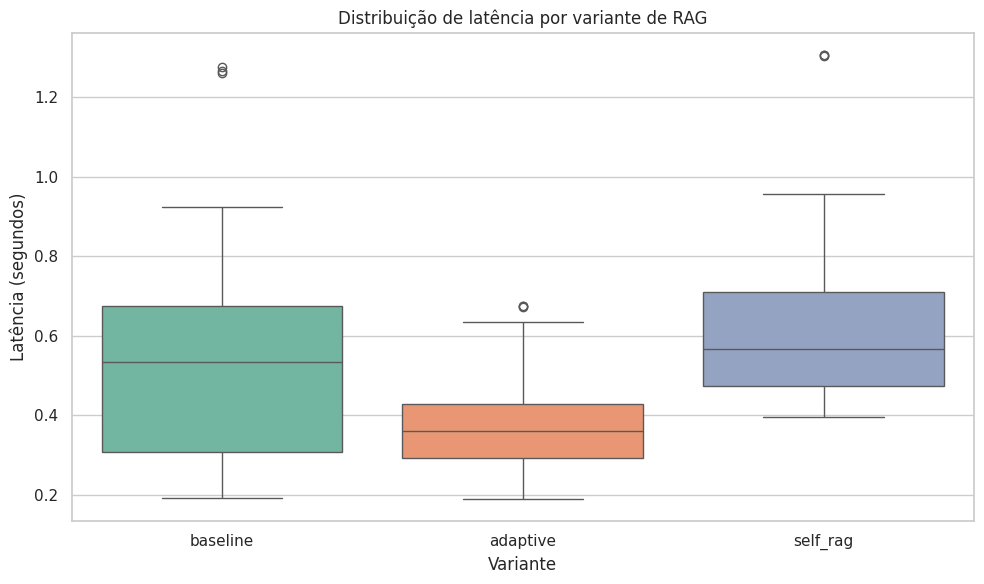

Figura gravada em: /content/results/imagem/boxplot_latencia.png


In [459]:
# Boxplot de latência v2
import seaborn as sns
import matplotlib.pyplot as plt

IMAGE_DIR = RESULTS_DIR / 'imagem'
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=official_df, x='variant', y='latency_sec', hue='variant',
            palette='Set2', legend=False, ax=ax)
ax.set_title('Distribuição de latência por variante de RAG')
ax.set_xlabel('Variante')
ax.set_ylabel('Latência (segundos)')
fig.tight_layout()

out_png = IMAGE_DIR / 'boxplot_latencia.png'
fig.savefig(out_png, dpi=150)
plt.show()

assert out_png.exists(), f'Figura não gravada em {out_png}'
print('Figura gravada em:', out_png)

### 📊 Relatório Final Consolidado

Abaixo, geramos a tabela comparativa geral (tiers, chamadas de LLM e latência) e a análise visual mapeando corretamente os nomes para **baseline**, **Adaptive RAG** e **Self-RAG**.

In [ ]:
# Relatório base v2: mapeamento de nomes, performance e abstenção por variante
name_mapping = {
    'baseline': 'Baseline', 'pure_llm': 'LLM puro',
    'adaptive_route': 'Adaptive (rota)', 'adaptive_expansion': 'Adaptive (expansão)',
    'adaptive_full': 'Adaptive (completo)', 'self_rag': 'Self-RAG',
    'embedding': 'Embedding',
}
df_mapped = official_df.copy()
df_mapped['variant'] = df_mapped['variant'].map(name_mapping)
ORDER = list(name_mapping.values())

performance_table = df_mapped.groupby('variant', as_index=False).agg(
    latencia_media_s=('latency_sec', 'mean'),
    chamadas_llm_medias=('llm_calls', 'mean'),
    rounds_retrieval_medios=('retrieval_rounds', 'mean'),
    evidencias_medias=('evidence_count', 'mean'),
)
performance_table['variant'] = pd.Categorical(performance_table['variant'],
                                              categories=ORDER, ordered=True)
performance_table = performance_table.sort_values('variant')

print(performance_table.round(3).to_string(index=False))


### Célula A (v2): Análise do ROTEADOR

Distribui os labels LABEL_A/B/C por questão e variante, compara com a dificuldade declarada (proxy de validação) e reporta os rounds de retrieval. Não recria as causas manuais da v1 (estão no snapshot).


In [ ]:
# Célula A (v2): análise do ROTEADOR — router_label × dificuldade + rounds
# A dificuldade declarada em questions.json é o proxy de validação dos labels:
# esperado = easy→LABEL_A, medium→LABEL_B, hard→LABEL_C.
router_rows = official_df[official_df['variant'].isin(['adaptive_route', 'adaptive_full'])]
assert router_rows['router_label'].notna().all(), 'linhas adaptativas sem router_label'

piv_lbl = router_rows.pivot_table(index='question_id', columns='variant',
                                  values='router_label', aggfunc='first')
dif = router_rows.drop_duplicates('question_id').set_index('question_id')['difficulty']

route_analysis = piv_lbl.join(dif)
route_analysis['difficulty_esperado'] = route_analysis['difficulty'].map(
    {'easy': 'LABEL_A', 'medium': 'LABEL_B', 'hard': 'LABEL_C'})
for variant_name in ['adaptive_route', 'adaptive_full']:
    route_analysis[f'match_{variant_name}'] = (
        route_analysis[variant_name] == route_analysis['difficulty_esperado'])
route_analysis.to_csv(RESULTS_DIR / 'router_analysis.csv')
print('=== Distribuição de router_label por variante (20q × 3 seeds) ===')
print(official_df.groupby(['variant', 'router_label']).size().to_string())
print('\n=== Rounds de retrieval por variante ===')
print(official_df.groupby(['variant', 'retrieval_rounds']).size().to_string())
print('\n=== Concordância com a dificuldade declarada ===')
print(route_analysis[['match_adaptive_route', 'match_adaptive_full']].mean().round(2).to_string())


# Célula B: sinal versus ruído
Esta célula mostra a acurácia de cada repetição e a média com desvio padrão entre repetições. Com 3 repetições, o desvio padrão é instável, então trate as barras de erro como indicação, não como intervalo de confiança.

In [ ]:
# Sinal vs ruído v2: acurácia por repetição (SEED DIFERENTE POR REPETIÇÃO)
import matplotlib.pyplot as plt

por_rep = g.groupby(['variant', 'repetition'])['ok'].mean().reset_index()
por_rep = por_rep.rename(columns={'ok': 'acuracia'})

resumo_var = (por_rep.groupby('variant')['acuracia']
              .agg(media='mean', desvio_padrao='std')
              .reindex(ORDER)
              .round(3))
display(por_rep.pivot(index='variant', columns='repetition', values='acuracia')
        .reindex(ORDER).round(3))
display(resumo_var)

IMAGE_DIR = RESULTS_DIR / 'imagem'
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(resumo_var.index, resumo_var['media'], yerr=resumo_var['desvio_padrao'],
       capsize=6)
ax.set_ylim(0, 1)
ax.set_ylabel('Acurácia (juiz não validado)')
ax.set_title('Acurácia por variante (desvio = variância entre seeds 42/43/44)')
fig.tight_layout()
fig.savefig(IMAGE_DIR / 'acuracia_sinal_ruido.png', dpi=150)
plt.show()


# Célula C: divergências entre variantes
Esta célula lista as perguntas em que as variantes divergem na mesma repetição, junto com as respostas. Essa é a lista que o item 3 pede, com as causas a serem registradas com base na célula A.

In [ ]:
# Célula C (v2): divergência de veredito entre variantes por repetição
verdicts_piv = g.pivot_table(index=['question_id', 'repetition'], columns='variant',
                             values='verdict', aggfunc='first')
mask_div = verdicts_piv.nunique(axis=1) > 1
divergencias = verdicts_piv[mask_div].reset_index()
divergencias.to_csv(RESULTS_DIR / 'divergencias_variantes.csv', index=False)
n_q = divergencias['question_id'].nunique()
print(f'{len(divergencias)} execuções com veredito divergente entre variantes '
      f'({n_q} questões distintas). Inspeção de causa: traces v2.')
display(divergencias)


# Chamadas ao LLM e latência por dificuldade (visualização)

A figura abaixo traz dois painéis. No primeiro, a média de chamadas ao LLM por variante: 1,0 para baseline e Adaptive RAG, e cerca de 2,3 para o Self-RAG, que faz uma chamada de rascunho e verificação e, quando há revisão, uma chamada adicional. No segundo, a latência média por nível de dificuldade (fácil, médio e difícil), separada por variante.

![Média de chamadas ao LLM e latência média por dificuldade](imagem/chamadas_e_latencia.png)

**Leitura:** o número de chamadas explica boa parte da diferença de latência entre o Self-RAG e as demais variantes. Como as variantes foram executadas em blocos sequenciais, com aquecimento antes de cada uma, diferenças de latência também podem refletir o estado do servidor. Os grupos de dificuldade têm tamanhos diferentes (15, 12 e 33 execuções por variante, conforme a distribuição do corpus), então comparações entre níveis devem considerar o tamanho amostral.

In [ ]:
# Chamadas ao LLM e latência por dificuldade — full roster
import seaborn as sns
import matplotlib.pyplot as plt

IMAGE_DIR = RESULTS_DIR / 'imagem'
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

assert 'chamadas_llm_medias' in performance_table.columns, \
    'Rode a célula do relatório base antes desta.'

latency_diff = df_mapped.groupby(['variant', 'difficulty'],
                                 as_index=False)['latency_sec'].mean()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.barplot(data=performance_table, x='variant', y='chamadas_llm_medias',
            order=ORDER, hue='variant', hue_order=ORDER, palette='viridis',
            legend=False, ax=axes[0])
axes[0].set_title('Média de chamadas ao LLM por variante')
axes[0].set_xlabel('Variante'); axes[0].set_ylabel('Chamadas (média)')
axes[0].tick_params(axis='x', rotation=30)

sns.barplot(data=latency_diff, x='difficulty', y='latency_sec',
            hue='variant', hue_order=ORDER, palette='magma', ax=axes[1])
axes[1].set_title('Latência média por dificuldade')
axes[1].set_xlabel('Dificuldade'); axes[1].set_ylabel('Latência (s)')
fig.tight_layout()
out_png = IMAGE_DIR / 'chamadas_e_latencia.png'
fig.savefig(out_png, dpi=150)
plt.show()
assert out_png.exists()
print('Figura gravada em:', out_png)


### 🎯 Avaliação Qualitativa das Chamadas

Para avaliar quantitativamente a qualidade semântica das respostas de cada variante, analisamos:
- **Tamanho médio das respostas (caracteres)**: Respostas muito curtas podem indicar falta de informação, enquanto respostas longas demais podem trazer ruído.
- **Taxa de Abstenção (fallback)**: frequência de respostas em que o modelo declara explicitamente que não pôde responder por falta de contexto, medida de forma única por `is_abstention()` (regex versionada em `prompts/abstention.txt`). **Não é taxa de alucinação**: abstenção é o comportamento contrário à alucinação (afirmar algo sem suporte no contexto), que esta métrica não mede.


In [ ]:
# 1. Comprimento das respostas e taxa de abstenção (fonte única)
df_mapped['answer_length'] = df_mapped['answer'].astype(str).str.len()

df_mapped['fallback_triggered'] = df_mapped['answer'].astype(str).apply(is_abstention)

quality_summary = df_mapped.groupby('variant').agg(
    comprimento_medio_caracteres=('answer_length', 'mean'),
    taxa_abstencao_fallback=('fallback_triggered', 'mean')
).reindex(ORDER).reset_index()

print('=== MÉTRICAS DE QUALIDADE DAS RESPOSTAS ===')
display(quality_summary)


In [ ]:
# Figura de qualidade v2 (substitui a celula morta FALLBACK_RE da v1)
import seaborn as sns
import matplotlib.pyplot as plt

IMAGE_DIR = RESULTS_DIR / 'imagem'
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

# por-execucao; nomes agregados ficam no quality_summary
q = df_mapped.assign(abstencao=df_mapped['fallback_triggered'])

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.barplot(data=q, x='variant', y='answer_length', order=ORDER,
            hue='variant', hue_order=ORDER, palette='viridis', legend=False,
            estimator='mean', ax=axes[0])
axes[0].set_title('Comprimento medio das respostas')
axes[0].tick_params(axis='x', rotation=30)
sns.barplot(data=q, x='variant', y='fallback_triggered', order=ORDER,
            hue='variant', hue_order=ORDER, palette='magma', legend=False,
            estimator='mean', ax=axes[1])
axes[1].set_title('Taxa de abstencao (heuristica lexical, fonte unica)')
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis='x', rotation=30)

fig.tight_layout()
out_png = IMAGE_DIR / 'qualidade_respostas.png'
fig.savefig(out_png, dpi=150)
plt.show()
assert out_png.exists()
print('Figura gravada em:', out_png)


#### 4. Conclusões e análise de sinal vs. ruído (v2)

**Preencher após a run v2.** Estrutura da leitura:
1. **Cobertura × precisão condicional** (métrica primária, `coverage_precision.csv`):
   cada variante respondeu em quanto % das execuções e acertou em quanto % das
   respostas dadas.
2. **Acurácia bruta** (secundária; `accuracy_summary.csv`): mistura abstenção com
   erro — nunca citada sozinha.
3. **Sinal vs. ruído** (`acuracia_sinal_ruido.png`): repetições agora têm seeds
   42/43/44 — o desvio entre repetições é variância amostral real (a v1 tinha
   58/60 respostas idênticas entre repetições).
4. **Auto-concordância do juiz**: exigência de ≥ 90% embarcada no grader.
5. **Roteador** (`router_analysis.csv`): labels vs dificuldade declarada; rounds
   seguem a política LABEL_A=0 / LABEL_B=1 / LABEL_C≤2.
6. **Latência**: só intra-v2 — hardware distinto (campo `gpu` no manifest v2).

**Limitações.**
- Juiz automático não validado contra avaliação manual (Fase 4 do plano).
- Abstenção: heurística lexical unificada (`prompts/abstention.txt`).
- 20 questões e 3 repetições: resultados são indicativos, não conclusivos.
- Proveniência: rubrica do gabarito definida ANTES da run v2 (ao contrário da v1).
